<a href="https://colab.research.google.com/github/blsribeiro83/mba-data-science/blob/main/08-%20deep-learning/aurelien_geron/Notas_Estudo_Geron_Cap03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Classificação**

Regressão (predição de valores) e classificação (predição de classes) são as tarefas de aprendizado supervisionado mais comuns.


MNIST é um conjunto de dados bastante popular para estudar aprendizado de máquinas, e consiste em 70mil imagens de pequenos algarismos escritos por estudantes do ensino médio e funcionários do censo nos EUA.

In [12]:
# obtendo os dados do MNIST

from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784",as_frame=False)

In [13]:
mnist

{'data': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]]),
 'target': array(['5', '0', '4', ..., '4', '5', '6'], dtype=object),
 'frame': None,
 'categories': {'class': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']},
 'feature_names': ['pixel1',
  'pixel2',
  'pixel3',
  'pixel4',
  'pixel5',
  'pixel6',
  'pixel7',
  'pixel8',
  'pixel9',
  'pixel10',
  'pixel11',
  'pixel12',
  'pixel13',
  'pixel14',
  'pixel15',
  'pixel16',
  'pixel17',
  'pixel18',
  'pixel19',
  'pixel20',
  'pixel21',
  'pixel22',
  'pixel23',
  'pixel24',
  'pixel25',
  'pixel26',
  'pixel27',
  'pixel28',
  'pixel29',
  'pixel30',
  'pixel31',
  'pixel32',
  'pixel33',
  'pixel34',
  'pixel35',
  'pixel36',
  'pixel37',
  'pixel38',
  'pixel39',
  'pixel40',
  'pixel41',
  'pixel42',
  'pixel43',
  'pixel44',
  'pixel45',
  'pixel46',
  'pixel47

In [14]:
X,y = mnist.data,mnist.target

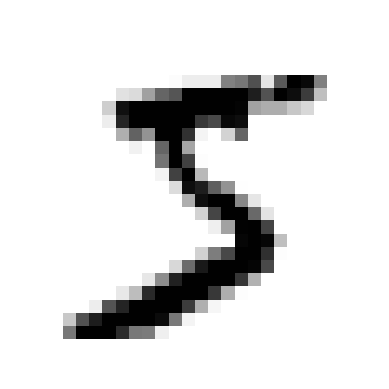

In [15]:
# para visualizar os caracteres, deve-se usar um mapa de 28x28 pixels, em que 0 é branco e 1 é preto

import matplotlib.pyplot as plt

def plot_digit(image_data):
  image = image_data.reshape(28,28)
  plt.imshow(image,cmap="binary")
  plt.axis("off")

some_digit = X[0]
plot_digit(some_digit)
plt.show()

In [16]:
y[2]

'4'

In [17]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:],y[:60000],y[60000:]

In [18]:
# criando um classificador binário. ex: 5

y_train_5 = (y_train == "5")

y_test_5 = (y_test=="5")

In [11]:
# escolher um classificador e treinar o conjunto de dados de teste e treino
# vamos usar a classe SGDClassifier - Classificador Descendente Estocástico

from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train,y_train_5)

SGDClassifier(random_state=42)

In [19]:
sgd_clf.predict([some_digit])

array([ True])

In [20]:
# avaliando acurária com validação cruzada

# usaremos a função cross_val_score() para avaliar o método SGDClassifier com o método kfold de validação cruzada

# método k-fold de validação cruzada - dividir o conjunto em k folds de treinamento
# e treinar o modelo k vezes, separando um fold diferente a cada treino


from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf,X_train,y_train_5,cv=3,scoring = "accuracy")



array([0.95035, 0.96035, 0.9604 ])

In [21]:
# Classificador para classe negativa (neste caso, o não-5)

from sklearn.base import BaseEstimator
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()

In [22]:
cross_val_score(dummy_clf,X_train,y_train_5,cv=3,scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

Nota: o resultado de acurácia acima acontece porque cerca de 10% das imagens são 5, assim, caso sempre estime que uma imagem *não* é 5, terá razão em cerca de 90% das vezes

Este resultado demonstra a importância de se utilizar **matrizes de confusão**

A ideia geral de uma **matriz de confusão** é *contabilizar* a quantidade de vezes que uma instância A é classificada como B, para todos os pares A/B. É necessário ter um conjunto de predições de modo que ele possa ser comparado com os alvos reais.

In [23]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf,X_train,y_train_5,cv=3)

In [25]:
y_train_pred

array([ True, False, False, ...,  True, False, False])

In [27]:
# criando uma matriz de confusão

from sklearn.metrics import confusion_matrix

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_train_5,y_train_pred)

cm

array([[53892,   687],
       [ 1891,  3530]])

In [28]:
# na matriz de confusão, cada linha representa uma classe real, e cada coluna representa uma classe prevista
# no exemplo anterior, a linha de cima representa tanto os verdadeiros negativos (53.892) quanto os falsos positivos (687)
# a linha de baixo representa os falsos negativos (1.891) quanto os verdadeiros positivos (3.350)

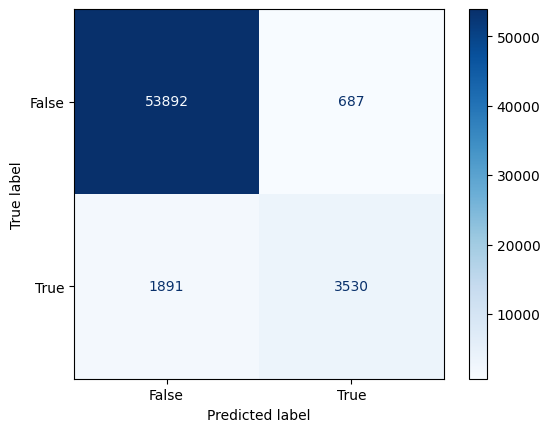

In [35]:
ConfusionMatrixDisplay.from_predictions(y_train_5,y_train_pred,cmap=plt.cm.Blues)
plt.show()

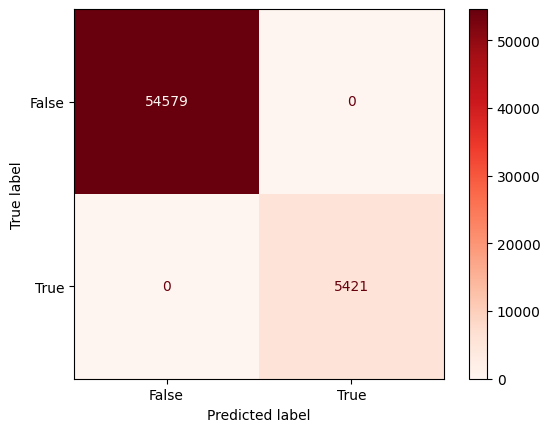

In [39]:
# simulando um classificador perfeito

y_train_perfect_predictions = y_train_5 #fingir que alcançamos a perfeição

ConfusionMatrixDisplay.from_predictions(y_train_5,y_train_perfect_predictions,cmap=plt.cm.Reds)
plt.show()

**Precisão do classificador**

A **precisão** mede a confiabilidade das previsões positivas. Ela é especialmente importante quando os falsos positivos são custosos.

Diz respeito à confiabilidade dos alertas emitidos pelo modelo.

TP = número de verdadeiros positivos e FP = número de falsos positivos

$$ \text{precisão} = \frac{\text{TP}}{\text{TP} + \text{FP}} $$

**Revocação ou sensibilidade do classificador**


Entre todos os positivos, quantos o modelo conseguiu efetivamente prever?

Sensibilidade diz respeito à capacidade de encontrar os eventos que realmente ocorreram.

TP = total de verdadeiros positivos, FN = total de falsos negativos

$$ \text{sensibilidade} = \frac{\text{TP}}{\text{TP} + \text{FN}} $$

In [41]:
# calculando precisão e sensibilidade

from sklearn.metrics import precision_score, recall_score

precision_score(y_train_5,y_train_pred)


0.8370879772350012

In [42]:
recall_score(y_train_5,y_train_pred)

0.6511713705958311